# Exploratory Data Analysis (EDA) on Superstore Retail Sales

**Goal:** analyse customer purchase volume, monthly seasonality, category-wise revenue and discount sensitivity, then give at least 5 executive takeaways.

**Workflow:** Loading -> Inspecting dataset -> Clean (nulls, duplicates, dates, Year/Month) -> Group (Category / Region / Segment) -> Plot -> Executive takeaways

## Step 1: Load the data and take a first look

In [9]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="notebook")
pd.options.display.float_format = "{:,.2f}".format

raw = pd.read_csv("superstore_sales.csv")
print("Raw shape:", raw.shape)
raw.head()

Raw shape: (10800, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,"42,420.00",South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2.00,0.00,41.91
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,"42,420.00",South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3.00,0.00,219.58
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,"90,036.00",West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2.00,0.00,6.87
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,"33,311.00",South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58,5.00,0.45,-383.03
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,"33,311.00",South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37,2.00,0.20,2.52


In [10]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10800 non-null  str    
 1   Order ID       10800 non-null  str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9983 non-null   float64
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       99

In [11]:
#Missing values of the RAW file
raw.isnull().sum()

Row ID             0
Order ID           0
Order Date       806
Ship Date        806
Ship Mode        806
Customer ID      806
Customer Name    806
Segment          806
Country          806
City             806
State            806
Postal Code      817
Region           806
Product ID       806
Category         806
Sub-Category     806
Product Name     806
Sales            806
Quantity         806
Discount         806
Profit           806
dtype: int64

**Observation:** the raw file has 10,800 rows and 806 missing values in almost all of the columns. That is cannot be right , because a real order table would not be missing the same rows everywhere. Lets look at the rows that have blanks. 

In [41]:
# Look at the rows where Order Date is missing
raw[raw["Order Date"].isnull()].iloc[[0, 1, 5, 6, 7, 8, -1], :4]

,Row ID,Order ID,Order Date,Ship Date
9994,Person,Region,NaN,NaN
9995,Anna Andreadi,West,NaN,NaN
9999,Returned,Order ID,NaN,NaN
10000,Yes,CA-2015-100762,NaN,NaN
10001,Yes,CA-2015-100762,NaN,NaN
10002,Yes,CA-2015-100762,NaN,NaN
10799,Yes,US-2018-155999,NaN,NaN


**Finding:** the file is three sheets of the original Superstore workbook stacked into one CSV(there are 3 tables in one csv):

| Rows | What they really are |
|---|---|
| first 9,994 | **Orders** (the real sales data) |
| next 5 | **People** sheet (regional managers) |
| last 800 | **Returns** sheet (order IDs that were returned) |

The 806 "missing values" are not missing data. They are other tables made under(after)the orders table. Dropping or filling them would be wrong. The correct fix is to separate the tables.

## Step 2: Clean the data

### a. Separate the Orders, People and Returns tables

In [42]:
# Real order table rows have a numeric Row ID; the other sheets do not
is_order = pd.to_numeric(raw["Row ID"], errors="coerce").notna()

orders  = raw[is_order].copy() #keeps only 'true' rows
returns = (raw.loc[raw["Row ID"] == "Yes", ["Order ID"]]
              .drop_duplicates()
              .reset_index(drop=True))

print("Orders rows :", len(orders))
print("Returned order IDs:", len(returns))

Orders rows : 9994
Returned order IDs: 296


### b. Fix data types

In [43]:
df = orders.copy()
df["Row ID"]   = df["Row ID"].astype(int)
df["Quantity"] = df["Quantity"].astype(int)  #was float because of the attached table rows
df.dtypes

Row ID             int64
Order ID             str
Order Date           str
Ship Date            str
Ship Mode            str
Customer ID          str
Customer Name        str
Segment              str
Country              str
City                 str
State                str
Postal Code      float64
Region               str
Product ID           str
Category             str
Sub-Category         str
Product Name         str
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object

### c. Missing value profile of the clean orders table

In [15]:
missing = df.isnull().sum()
missing[missing > 0]

Postal Code    11
dtype: int64

In [16]:
# Which rows are missing a Postal Code?
df[df["Postal Code"].isnull()][["City", "State"]].drop_duplicates()

,City,State
2234,Burlington,Vermont


**Decision:** only 11 Postal Codes are missing , and all belong to Burlington ,Vermont (ZIP 05401). Postal code is not used in our analysis , but filling it is easy and keeps the table complete. I stored ZIPs as text with 5 digits so codes like '01040' do not lose their leading zero.

In [17]:
df["Postal Code"] = df["Postal Code"].fillna(5401).astype(int).astype(str).str.zfill(5)
print("Missing values left:", df.isnull().sum().sum())

Missing values left: 0


### d. Duplicates

In [18]:
# Row ID is unique per row , so ignore it when checking for repeated records
dup_cols = df.columns.difference(["Row ID"])
print("Duplicate rows:", df.duplicated(subset=dup_cols).sum())
df[df.duplicated(subset=dup_cols, keep=False)]

Duplicate rows: 1


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
3405,3406,US-2015-150119,4/23/2015,4/27/2015,Standard Class,LB-16795,Laurel Beltran,Home Office,United States,Columbus,...,43229,East,FUR-CH-10002965,Furniture,Chairs,Global Leather Highback Executive Chair with P...,281.37,2,0.30,-12.06
3406,3407,US-2015-150119,4/23/2015,4/27/2015,Standard Class,LB-16795,Laurel Beltran,Home Office,United States,Columbus,...,43229,East,FUR-CH-10002965,Furniture,Chairs,Global Leather Highback Executive Chair with P...,281.37,2,0.30,-12.06


In [19]:
df = df.drop_duplicates(subset=dup_cols).reset_index(drop=True)
print("Rows after removing duplicates:", len(df))

Rows after removing duplicates: 9993


**Decision:** one order line (order `US-2015-150119`, a Global Leather chair) appears twice with identical values , so the second copy is dropped to avoid double counting.

### e. Parse dates and create Year-Month

In [20]:
# The file uses US format: month/day/year (e.g. 11/8/2017 = 8 Nov 2017)
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y")
df["Ship Date"]  = pd.to_datetime(df["Ship Date"],  format="%m/%d/%Y")

df["Year"]      = df["Order Date"].dt.year
df["Month"]     = df["Order Date"].dt.month
df["YearMonth"] = df["Order Date"].dt.to_period("M")

print("Date range:", df["Order Date"].min().date(), "to", df["Order Date"].max().date())
df[["Order Date", "Ship Date", "Year", "Month", "YearMonth"]].head()

Date range: 2015-01-03 to 2018-12-30


,Order Date,Ship Date,Year,Month,YearMonth
0,2017-11-08,2017-11-11,2017,11,2017-11
1,2017-11-08,2017-11-11,2017,11,2017-11
2,2017-06-12,2017-06-16,2017,6,2017-06
3,2016-10-11,2016-10-18,2016,10,2016-10
4,2016-10-11,2016-10-18,2016,10,2016-10


### f. Sanity checks (logic checks on the values)

In [21]:
checks = {
    "Ship date before order date": (df["Ship Date"] < df["Order Date"]).sum(),
    "Sales <= 0":                  (df["Sales"] <= 0).sum(),
    "Quantity <= 0":               (df["Quantity"] <= 0).sum(),
    "Discount outside 0-1":        (~df["Discount"].between(0, 1)).sum(),
}
pd.Series(checks,name="Rows failing check")

Ship date before order date    0
Sales <= 0                     0
Quantity <= 0                  0
Discount outside 0-1           0
Name: Rows failing check, dtype: int64

In [22]:
# Mark which order lines belong to returned orders
df["Returned"] = df["Order ID"].isin(returns["Order ID"])

print("Final clean shape:",df.shape)
df.describe().T

Final clean shape: (9993, 25)


,count,mean,min,25%,50%,75%,max,std
Row ID,"9,993.00","4,997.66",1.00,"2,499.00","4,998.00","7,496.00","9,994.00","2,885.26"
Order Date,9993,2017-04-30 07:03:30.747523,2015-01-03 00:00:00,2016-05-23 00:00:00,2017-06-26 00:00:00,2018-05-14 00:00:00,2018-12-30 00:00:00,NaN
Ship Date,9993,2017-05-04 06:03:42.635845,2015-01-07 00:00:00,2016-05-27 00:00:00,2017-06-29 00:00:00,2018-05-18 00:00:00,2019-01-05 00:00:00,NaN
Sales,"9,993.00",229.85,0.44,17.28,54.48,209.94,"22,638.48",623.28
Quantity,"9,993.00",3.79,1.00,2.00,3.00,5.00,14.00,2.23
Discount,"9,993.00",0.16,0.00,0.00,0.20,0.20,0.80,0.21
Profit,"9,993.00",28.66,"-6,599.98",1.73,8.67,29.36,"8,399.98",234.27
Year,"9,993.00","2,016.72","2,015.00","2,016.00","2,017.00","2,018.00","2,018.00",1.12
Month,"9,993.00",7.81,1.00,5.00,9.00,11.00,12.00,3.28


**Cleaning summary**

| Issue | Action |
|---|---|
| People + Returns sheets glued to the orders (806 blank-looking rows) | Separated into their own tables |
| 11 missing Postal Codes (Burlington, VT) | Filled with 05401 |
| 1 duplicate order line | Removed |
| Dates stored as text | Converted with `%m/%d/%Y`, created `YearMonth` |
| Sales, Quantity, Discount values | Checked: no invalid values |

## Step 3: Overall KPIs and groupby analysis

In [23]:
total_sales  = df["Sales"].sum()
total_profit = df["Profit"].sum()

kpi = pd.Series({
    "Total sales ($)":   total_sales,
    "Total profit ($)":  total_profit,
    "Profit margin (%)": total_profit / total_sales * 100,
    "Orders":            df["Order ID"].nunique(),
    "Customers":         df["Customer ID"].nunique(),
    "Order lines":       len(df),
})
kpi

Total sales ($)     2,296,919.49
Total profit ($)      286,409.08
Profit margin (%)          12.47
Orders                  5,009.00
Customers                 793.00
Order lines             9,993.00
dtype: float64

In [24]:
def summarise(by):
    g = df.groupby(by).agg(Sales=("Sales", "sum"),
                           Profit=("Profit", "sum"),
                           Quantity=("Quantity", "sum"),
                           Avg_Discount=("Discount", "mean"))
    g["Margin_%"]      = g["Profit"] / g["Sales"] * 100
    g["Sales_Share_%"] = g["Sales"] / g["Sales"].sum() * 100
    return g.sort_values("Sales", ascending=False)

cat_summary = summarise("Category")
cat_summary

,Sales,Profit,Quantity,Avg_Discount,Margin_%,Sales_Share_%
Category,,,,,,
Technology,"836,154.03","145,454.95",6939,0.13,17.40,36.40
Furniture,"741,718.42","18,463.33",8026,0.17,2.49,32.29
Office Supplies,"719,047.03","122,490.80",22906,0.16,17.04,31.30


In [25]:
region_summary = summarise("Region")
region_summary

,Sales,Profit,Quantity,Avg_Discount,Margin_%,Sales_Share_%
Region,,,,,,
West,"725,457.82","108,418.45",12266,0.11,14.94,31.58
East,"678,499.87","91,534.84",10616,0.15,13.49,29.54
Central,"501,239.89","39,706.36",8780,0.24,7.92,21.82
South,"391,721.91","46,749.43",6209,0.15,11.93,17.05


In [26]:
segment_summary = summarise("Segment")
segment_summary

,Sales,Profit,Quantity,Avg_Discount,Margin_%,Sales_Share_%
Segment,,,,,,
Consumer,"1,161,401.34","134,119.21",19521,0.16,11.55,50.56
Corporate,"706,146.37","91,979.13",11608,0.16,13.03,30.74
Home Office,"429,371.78","60,310.74",6742,0.15,14.05,18.69


In [27]:
# Sub-Category drill-down (explains why Furniture is weak)
sub_summary = summarise("Sub-Category").sort_values("Profit")
sub_summary[["Sales", "Profit", "Margin_%"]]

,Sales,Profit,Margin_%
Sub-Category,,,
Tables,"206,965.53","-17,725.48",-8.56
Bookcases,"114,880.00","-3,472.56",-3.02
Supplies,"46,673.54","-1,189.10",-2.55
Fasteners,"3,024.28",949.52,31.40
Machines,"189,238.63","3,384.76",1.79
Labels,"12,486.31","5,546.25",44.42
Art,"27,118.79","6,527.79",24.07
Envelopes,"16,476.40","6,964.18",42.27
Furnishings,"91,705.16","13,059.14",14.24


In [28]:
# Category x Region profit table
df.pivot_table(values="Profit", index="Region", columns="Category", aggfunc="sum")

Category,Furniture,Office Supplies,Technology
Region,,,
Central,"-2,871.05","8,879.98","33,697.43"
East,"3,058.22","41,014.58","47,462.04"
South,"6,771.21","19,986.39","19,991.83"
West,"11,504.95","52,609.85","44,303.65"


### Customer purchase volume

In [29]:
cust = df.groupby("Customer ID").agg(Orders=("Order ID", "nunique"),
                                     Sales=("Sales", "sum"),
                                     Profit=("Profit", "sum"))

print("Average orders per customer:", round(cust["Orders"].mean(), 1))
print("Median orders per customer :", cust["Orders"].median())
print("Average sales per customer : $", round(cust["Sales"].mean(), 0))

top10_n = int(len(cust) * 0.10)
top10_share = cust["Sales"].nlargest(top10_n).sum() / cust["Sales"].sum() * 100
print(f"Top 10% of customers ({top10_n}) generate {top10_share:.1f}% of sales")

Average orders per customer: 6.3
Median orders per customer : 6.0
Average sales per customer : $ 2896.0
Top 10% of customers (79) generate 30.6% of sales


### Returns (bonus)

In [30]:
returned_orders = df.loc[df["Returned"], "Order ID"].nunique()
print(f"Returned orders: {returned_orders} ({returned_orders / df['Order ID'].nunique() * 100:.1f}% of all orders)")
print(f"Sales on returned orders: ${df.loc[df['Returned'], 'Sales'].sum():,.0f} "
      f"({df.loc[df['Returned'], 'Sales'].sum() / total_sales * 100:.1f}% of total sales)")

Returned orders: 296 (5.9% of all orders)
Sales on returned orders: $180,504 (7.9% of total sales)


## Step 4: Visualisations

### Chart 1: Monthly sales velocity (seasonality)

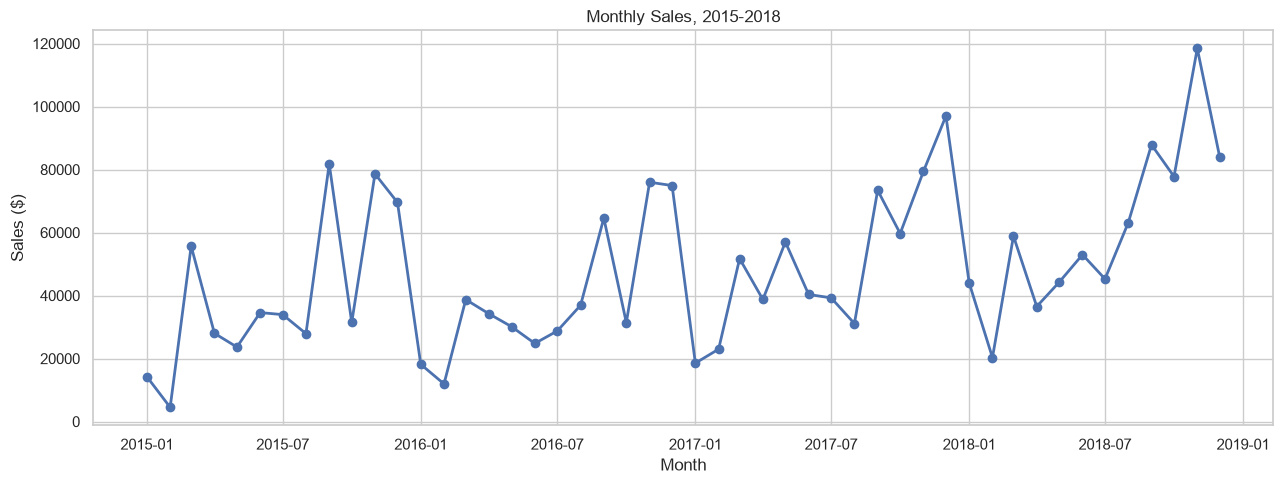

In [31]:
monthly = df.groupby("YearMonth")["Sales"].sum()
monthly.index = monthly.index.to_timestamp()

plt.figure(figsize=(13, 5))
plt.plot(monthly.index, monthly.values, marker="o", linewidth=2)
plt.title("Monthly Sales, 2015-2018")
plt.xlabel("Month")
plt.ylabel("Sales ($)")
plt.tight_layout()
plt.show()

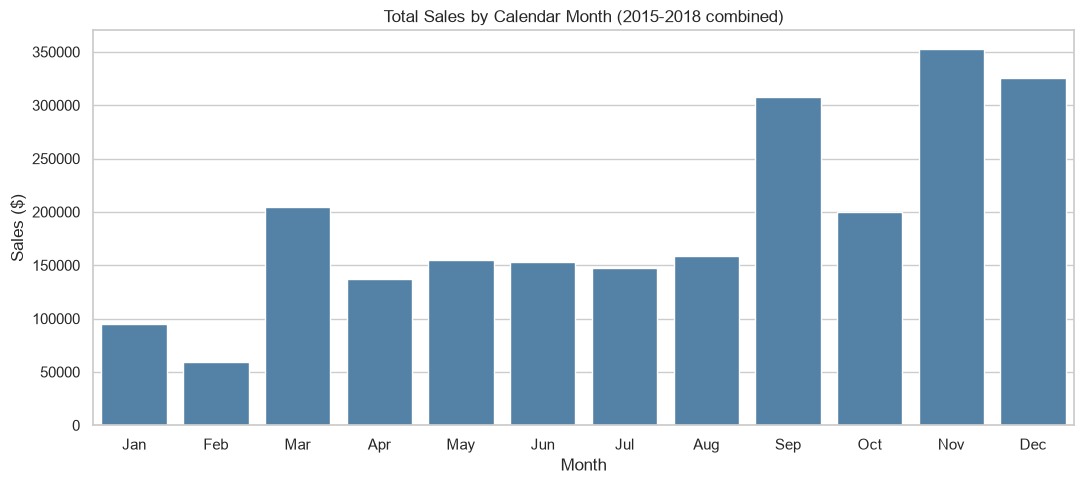

Month
Jan    4.10
Feb    2.60
Mar    8.90
Apr    6.00
May    6.70
Jun    6.60
Jul    6.40
Aug    6.90
Sep   13.40
Oct    8.70
Nov   15.30
Dec   14.20
Name: Sales, dtype: float64


In [32]:
# Seasonality: total sales by calendar month (all years combined)
by_month = df.groupby("Month")["Sales"].sum()
month_names = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

plt.figure(figsize=(11, 5))
ax = sns.barplot(x=month_names, y=by_month.values, color="steelblue")
ax.set_title("Total Sales by Calendar Month (2015-2018 combined)")
ax.set_xlabel("Month")
ax.set_ylabel("Sales ($)")
plt.tight_layout()
plt.show()

print((by_month / by_month.sum() * 100).round(1).rename(dict(zip(range(1, 13), month_names))))

**Insight:** sales follows a clear yearly pattern. **September,November and December** are the peaks (13.4%,15.3% and 14.2% of all sales, together about 43%). **January and February** are the weakest months(4.1% and 2.6%). The overall trend is also upward from 2016 onward .

### Chart 2 : Sales and profit by Category

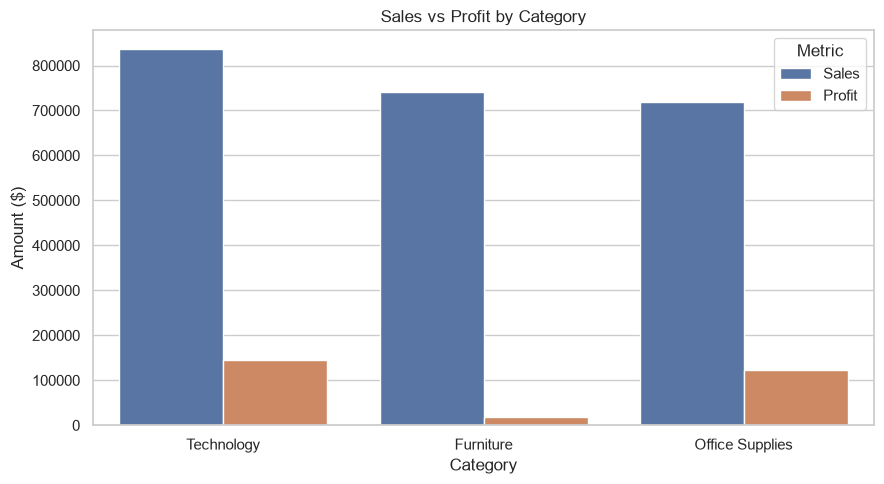

In [33]:
cat_plot = cat_summary[["Sales","Profit"]].reset_index().melt(id_vars="Category", var_name="Metric",value_name="Amount")

plt.figure(figsize=(9, 5))
sns.barplot(data=cat_plot, x="Category", y="Amount", hue="Metric")
plt.title("Sales vs Profit by Category")
plt.ylabel("Amount ($)")
plt.tight_layout()
plt.show()

**Insight :** Furnitures earns almost as much revenue as the other two categories ($742K) but only **$18K profit (2.5% margin)**, versus about 17% for Technology and Office Supplies.

### Chart 3: Profit by Sub Category

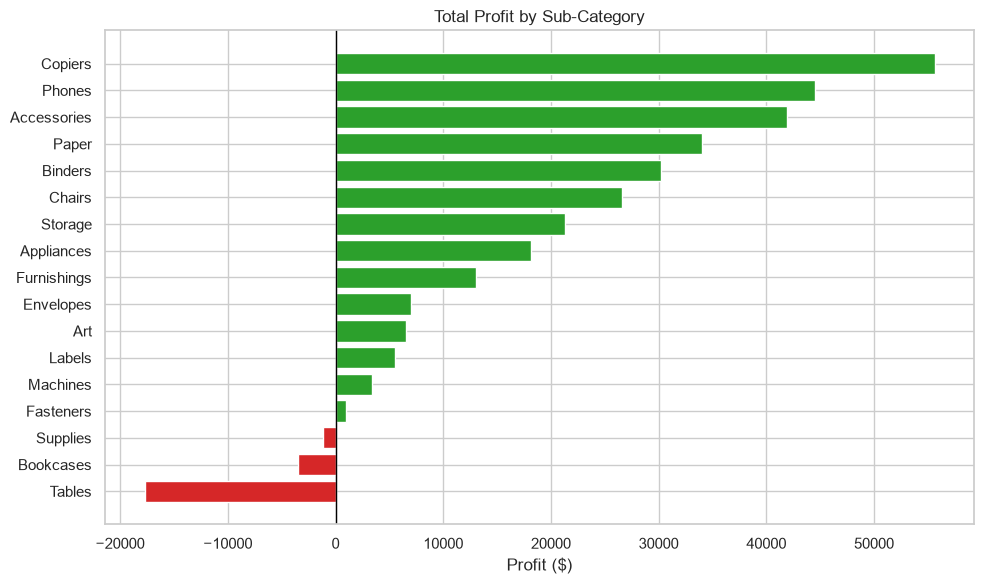

In [34]:
plt.figure(figsize=(10, 6))
colors = ["#d62728" if p < 0 else "#2ca02c" for p in sub_summary["Profit"]]
plt.barh(sub_summary.index, sub_summary["Profit"], color=colors)
plt.axvline(0, color="black", linewidth=1)
plt.title("Total Profit by Sub-Category")
plt.xlabel("Profit ($)")
plt.tight_layout()
plt.show()

**Insight:** three sub categories lose money: Tables (-$17.7k) , bookcases (-$3.5K) and Supplies (-$1.2K). Tables and Bookcases are the reason Furniture is so weak.

### Chart 4: Profit by Region and Segment

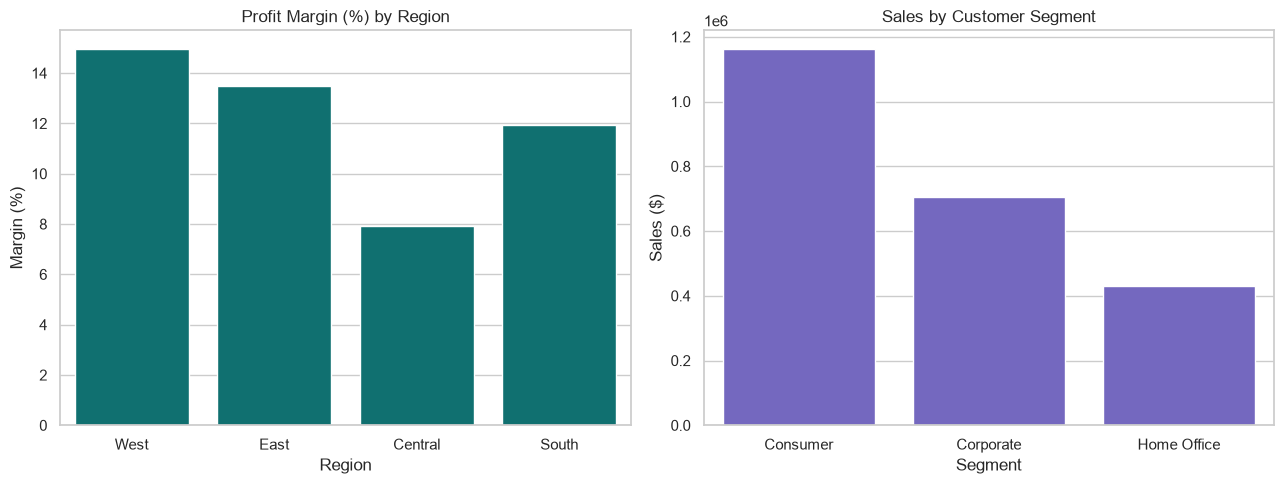

In [35]:
fig , axes = plt.subplots(1 , 2 , figsize=(13, 5))

sns.barplot(x=region_summary.index, y=region_summary["Margin_%"], color="teal", ax=axes[0])
axes[0].set_title("Profit Margin (%) by Region")
axes[0].set_ylabel("Margin (%)")

sns.barplot(x=segment_summary.index, y=segment_summary["Sales"], color="slateblue", ax=axes[1])
axes[1].set_title("Sales by Customer Segment")
axes[1].set_ylabel("Sales ($)")

plt.tight_layout()
plt.show()

**Insight:** the **West** has the best margin (14.9%) and the **Central** region the worst (7.9%), almost half. **Consumers** are the biggest segment by sales (about 51%), but **Home Office** has the best margin (14.1%).

### Chart 5: Discount vs Profit (discount sensitivity)

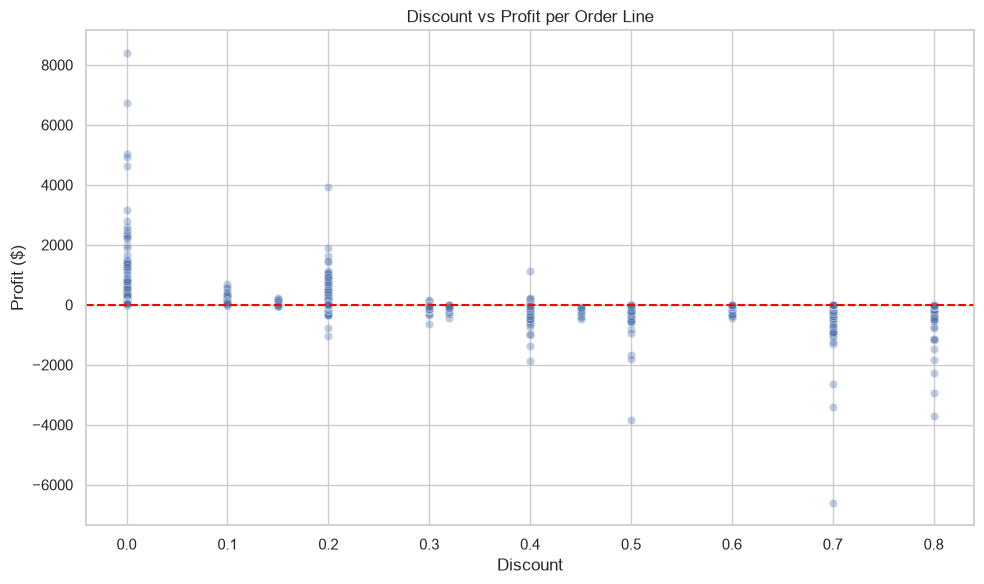

Correlation (Discount, Profit): -0.219


In [36]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="Discount", y="Profit", alpha=0.35)
plt.axhline(0, color="red", linestyle="--")
plt.title("Discount vs Profit per Order Line")
plt.xlabel("Discount")
plt.ylabel("Profit ($)")
plt.tight_layout()
plt.show()

print("Correlation (Discount, Profit):", round(df["Discount"].corr(df["Profit"]), 3))

In [37]:
df["Discount Band"] = pd.cut(df["Discount"], bins=[-0.001, 0, 0.2, 1.0],
                             labels=["No discount", "Up to 20%", "Above 20%"])

band = df.groupby("Discount Band", observed=True).agg(Lines=("Profit", "size"),
                                                      Sales=("Sales", "sum"),
                                                      Profit=("Profit", "sum"))
band["Share_of_lines_%"]   = band["Lines"] / band["Lines"].sum() * 100
band["Loss_making_lines_%"] = (df.groupby("Discount Band", observed=True)["Profit"]
                                 .apply(lambda s: (s < 0).mean() * 100))
band

,Lines,Sales,Profit,Share_of_lines_%,Loss_making_lines_%
Discount Band,,,,,
No discount,4798,"1,087,908.47","320,987.60",48.01,0.00
Up to 20%,3803,"846,522.24","100,785.47",38.06,13.75
Above 20%,1392,"362,488.78","-135,364.00",13.93,96.77


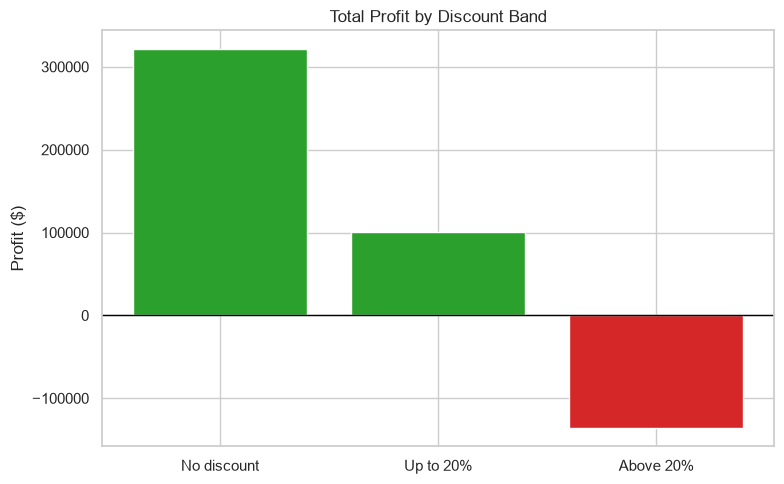

In [38]:
plt.figure(figsize=(8, 5))
colors = ["#2ca02c" if p > 0 else "#d62728" for p in band["Profit"]]
plt.bar(band.index.astype(str), band["Profit"], color=colors)
plt.axhline(0, color="black", linewidth=1)
plt.title("Total Profit by Discount Band")
plt.ylabel("Profit ($)")
plt.tight_layout()
plt.show()

**Insight:** profit falls as discount rises (correlation -0.22). Lines with **no discount or up to 20%** make a profit, but lines with **more than 20% discount** lose **$135K in total**, and about **97% of them are loss-making**.

### Chart 6: Where the heavy discounting happens

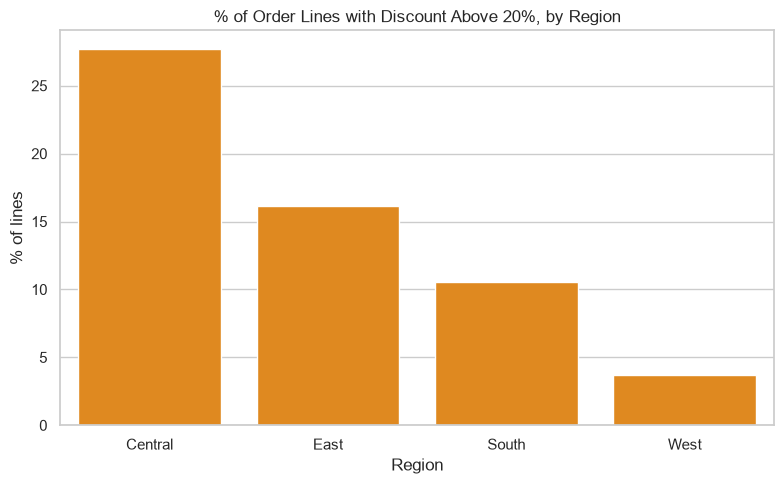

Region
Central   27.70
East      16.20
South     10.60
West       3.70
Name: Heavy, dtype: float64

In [39]:
heavy = (df.assign(Heavy=df["Discount"] > 0.2)
           .groupby("Region")["Heavy"].mean() * 100).sort_values(ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(x=heavy.index, y=heavy.values, color="darkorange")
plt.title("% of Order Lines with Discount Above 20%, by Region")
plt.ylabel("% of lines")
plt.tight_layout()
plt.show()
heavy.round(1)

**Insight:** **27.7%** of Central region lines carry a discount above 20%, compared with only **3.7%** in the West. This lines up with Central having the lowest margin.

## Step 5: Executive takeaways (business observations)

1. **The business is healthy and growing .** Total sales are about $2.3M with $286K profit (12.5% margin). Sales dipped 2.8% in 2016 , then grew **29.5% in 2017** and **20.4% in 2018**. *Action: keep investing in growth, but watch margins.*

2. **Sales are strongly seasonal.** September , November and December bring about **43% of annual sales** (Nov & Dec alone are 29.5%) , while January and February are the slowest months (4.1% and 2.6%). Action: build inventory and staffing before September and run promotions in the slow Q1 months.

3. **Furniture is hvaing a profit problem , not a sales problem.** It brings in 32% of revenue but only a **2.5% margin** (about $18K profit), versus roughly 17% for Technology and Office Supplies. Tables (-$17.7K)** and **Bookcases (-$3.5K)** lose money. Action: review pricing, supplier cost and discounts on Tables and Bookcases.

4. **Discounts above 20% destroys profit.** Lines with a discount above 20% are 14% of all lines but lose **$135K combined** , and about 97% of them are making losses . Lines with no discount or up to 20% earn about $422K. Action: cap discounts at 20% unless its approved.

5. **The Central region is the weak spot, and discounting explains it.** Central has a **7.9% margin** versus **14.9% in the West**. In Central , **27.7%** of lines have a discount above 20% (West: 3.7%), and Central Furniture is making loss (-$2.9K). Action: tighten the discount policy in Central first.

6. **Customers are loyal , and the top ones matters.** The 793 customers place about **6.3 orders each** on average. The **top 10% of customers generate 30.6% of sales**. Consumers are the largest segment (about 51% of sales) but have the lowest margin among segments (11.6%), while Home Office has the best (14.1%). *Action: create a loyalty programme for top customers and grow Home Office.*

7. **Returns are a noticeable leak.** **296 orders (5.9%)** were returned, covering about **$181K (7.9%) of sales**. *Action: find which products and regions drive the returns.*